## 7 · Final evaluation and interpretation

### By:
Sofía Arango Patiño

### Date:
2026-11-04

### Description:

Seventh step of the proof of concept ([issue #7](https://github.com/modsiw-mona/anomaly_detection_ato/issues/7);
CRISP-DM phase 5, *evaluation*; thesis objective **OE4**: Recall, Precision, PR-AUC, threshold and error analysis).

1. **Thresholds** chosen on the development side (out-of-fold scores from issue #6), never on the test side.
2. **The final measurement** — the selected model scores the **test side once** (20% of users, closed since
   issue #4). Nothing is tuned after this point.
3. **Consequences of each kind of error** — false alarms (legitimate users challenged) against missed takeovers.
4. **What the model relies on** — permutation importance by feature group and SHAP explanations.
5. **Error analysis** — which takeovers are missed, which legitimate logins are flagged, and why.
6. **Learning curve and scalability** on the test side.

Charts and the metrics report are written to `data/08_reporting/` (gitignored, like all data).

## 📚 Import libraries

In [1]:
import sys
from pathlib import Path

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import shap
from sklearn.base import clone

from data.datasets import load_dataset_config
from data.features import FEATURE_GROUPS
from data.split import load_side
from model.baselines import training_sample
from model.evaluation import bootstrap_pr_auc, evaluate
from model.preprocessing import to_model_frame
from model.selection import campaign_weights, group_metrics

warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")
pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(50)
pl.Config.set_tbl_width_chars(200)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 of the validated palette
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
        "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
    }
)  # fmt: skip


def subtitle(ax: plt.Axes, text: str) -> None:
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")


config = load_dataset_config("rba")
data_dir = REPO_ROOT / "data"
reports = data_dir / "08_reporting"
reports.mkdir(exist_ok=True)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(reports / f"{config.name}_{name}.png", dpi=150, bbox_inches="tight")

## 💾 Load the selected model (issue #6)

In [3]:
pipeline = joblib.load(data_dir / "06_models" / f"{config.name}_model.joblib")
meta = json.loads((data_dir / "06_models" / f"{config.name}_model.json").read_text())
columns = meta["columns"]
print("selected:", meta["selected"])
print(f"{len(columns)} input columns · campaign-balanced: {meta['campaign_balanced']}")
cv = meta["cv_15_folds"]
print(
    f"development estimate (15 folds): PR-AUC {cv['pr_auc (15 folds)']:.3f}, recall @1% {cv['recall_1pct']:.2f}"
)

selected: random forest (leaf 2) + campaign + travel, balanced
39 input columns · campaign-balanced: True
development estimate (15 folds): PR-AUC 0.448, recall @1% 0.89


## 🎚️ 1 · Thresholds, chosen on the development side

An alert budget is the share of logins a security team is willing to challenge. Two tiers, from the
out-of-fold development scores of issue #6 (each login scored by a model that never saw its user):

| Tier | Budget | Action |
| --- | --- | --- |
| **review / block** | top 0.1% | hold the session, analyst review |
| **step-up** | top 1% | ask for a second factor |
| allow | the rest | — |

The score thresholds are fixed **now**, before the test side is opened.

In [4]:
dev_oof = pl.read_parquet(data_dir / "07_model_output" / f"{config.name}_dev_oof.parquet")
BUDGETS = {"review / block": 0.001, "step-up": 0.01}
thresholds = {
    tier: float(np.quantile(dev_oof["score"].to_numpy(), 1 - b)) for tier, b in BUDGETS.items()
}
thresholds

{'review / block': 0.03332510201888003, 'step-up': 0.0033330654337646514}

## 🔓 2 · The final measurement — test side

The pipeline (preprocessing + model, refitted on the whole development side) scores every test login.

> **Note.** An earlier run of this notebook used a model with a preprocessing bug (unseen networks treated as clean),
> found in code review of issue #6 and fixed there; that run gave test PR-AUC 0.606 [0.434–0.765]. The numbers
> below are from the corrected model.

In [5]:
test = load_side(config, data_dir, "test").collect()
start = time.perf_counter()
score = pipeline.predict_proba(to_model_frame(test, columns))[:, 1]
scoring_seconds = time.perf_counter() - start
assert np.isfinite(score).all() and score.std() > 0, "scores must be finite and vary"
yt = test["label_ato"].to_numpy()
romania = (test["country"] == "RO").to_numpy()
print(
    f"test side: {test.height:,} logins, {int(yt.sum())} takeovers ({int((yt & romania).sum())} from RO), "
    f"{test['user_id'].n_unique():,} users · scored in {scoring_seconds:.1f} s"
)
pl.DataFrame({"event_id": test["event_id"], "score": score}).write_parquet(
    data_dir / "07_model_output" / f"{config.name}_test_scores.parquet"
)

test side: 1,971,980 logins, 28 takeovers (16 from RO), 553,756 users · scored in 3.3 s


In [6]:
final = evaluate(yt, score)
assert final["pr_auc"] < 0.95, "suspiciously high: check for leakage before reporting"  # noqa: PLR2004
low, high = bootstrap_pr_auc(yt, score)
by_group = group_metrics(yt, score, {"Romania": romania, "other": ~romania})
rows = [{"takeovers": name, "n": int((yt if name == "all" else yt & (romania if name == "Romania" else ~romania)).sum()), **m}
        for name, m in by_group.items()]  # fmt: skip
final_table = pl.DataFrame(rows).drop("prevalence").with_columns(pl.col(pl.Float64).round(4))
print(
    f"TEST PR-AUC {final['pr_auc']:.3f}  (bootstrap 95% interval {low:.3f}–{high:.3f}) · chance level {yt.mean():.1e}"  # noqa: RUF001
)
final_table

TEST PR-AUC 0.623  (bootstrap 95% interval 0.454–0.777) · chance level 1.4e-05


takeovers,n,pr_auc,roc_auc,recall_at_0_1pct,recall_at_1pct,precision_at_1pct,friction_at_1pct
str,i64,f64,f64,f64,f64,f64,f64
"""all""",28,0.6231,0.9996,0.8571,1.0,0.0014,0.01
"""Romania""",16,0.7146,0.9999,0.9375,1.0,0.0008,0.01
"""other""",12,0.3298,0.9991,0.75,1.0,0.0006,0.01


In [7]:
comparison = pl.DataFrame(
    {
        "metric": [
            "PR-AUC",
            "recall @0.1%",
            "recall @1%",
            "precision @1%",
            "recall @1%, Romania",
            "recall @1%, other",
        ],
        "development (15 folds, out-of-fold)": [
            cv["pr_auc (15 folds)"],
            cv["recall_0_1pct"],
            cv["recall_1pct"],
            cv["precision_1pct"],
            cv["recall_1pct_romania"],
            cv["recall_1pct_other"],
        ],
        "test (once)": [
            final["pr_auc"],
            final["recall_at_0_1pct"],
            final["recall_at_1pct"],
            final["precision_at_1pct"],
            by_group["Romania"]["recall_at_1pct"],
            by_group["other"]["recall_at_1pct"],
        ],
    }
).with_columns(pl.col(pl.Float64).round(4))
(reports / f"{config.name}_test_metrics.json").write_text(json.dumps(
    {"selected": meta["selected"], "test": final, "test_pr_auc_interval": [low, high],
     "by_group": by_group, "thresholds": thresholds}, indent=2))  # fmt: skip
comparison

metric,"development (15 folds, out-of-fold)",test (once)
str,f64,f64
"""PR-AUC""",0.4475,0.6231
"""recall @0.1%""",0.8129,0.8571
"""recall @1%""",0.8902,1.0
"""precision @1%""",0.0013,0.0014
"""recall @1%, Romania""",0.9839,1.0
"""recall @1%, other""",0.7733,1.0


**Reading (final measurement).** On the **28 test takeovers** (16 from RO), the selected model reaches **PR-AUC 0.62** (bootstrap 95% interval
0.45–0.78; chance is 1.4 × 10⁻⁵) and ranks **24 of 28 takeovers (86%) in the top 0.1%** of logins and **all 28 in
the top 1%**. The development estimate (0.45) lies inside the test interval: with 28 positives the test value is
itself uncertain, and its being higher is variance (the test side holds a slightly larger share of the easier
Romania campaign, 57% vs 55%), not a sign of leakage — the automatic check above stops the notebook if PR-AUC
exceeds 0.95. By group: Romania PR-AUC 0.71 (15 of 16 in the top 0.1%), other takeovers 0.33 (9 of 12). Precision
stays low at every budget (0.14% at 1%), the expected price of one takeover per 70,000 logins.

**Fixed thresholds on new data.** The budgets above rank the test logins among themselves. In production
the thresholds are fixed in advance, so the realised alert rate can drift; with the development thresholds:

In [8]:
tiers = []
for tier, t in thresholds.items():
    flagged = score >= t
    tiers.append({"tier (and stricter)": tier, "threshold": t, "alert rate": flagged.mean(),
                  "takeovers caught": int((flagged & yt).sum()), "recall": (flagged & yt).sum() / yt.sum(),
                  "precision": (flagged & yt).sum() / max(flagged.sum(), 1),
                  "legitimate challenged": int((flagged & ~yt).sum())})  # fmt: skip
tiers = pl.DataFrame(tiers).with_columns(pl.col(pl.Float64).round(5))
tiers

tier (and stricter),threshold,alert rate,takeovers caught,recall,precision,legitimate challenged
str,f64,f64,i64,f64,f64,i64
"""review / block""",0.03333,0.00094,24,0.85714,0.01291,1835
"""step-up""",0.00333,0.00949,28,1.0,0.0015,18692


## ⚖️ 3 · Consequences of each error

* **False negative** (missed takeover): an attacker keeps access to the account — fraud, data theft, lateral use of
  the identity. Costly and slow to discover (the incident response team found these weeks later).
* **False positive** (legitimate login flagged): at the *step-up* tier, a user is asked for a second factor — a few
  seconds of friction; at *review / block*, a legitimate session is held until an analyst clears it.

Per **one million logins** at this service's takeover rate, the test results translate into:

In [9]:
per_million = 1_000_000 / test.height
consequences = tiers.select(
    "tier (and stricter)",
    (pl.col("legitimate challenged") * per_million)
    .round(0)
    .alias("legitimate users challenged / 1M logins"),
    (pl.col("takeovers caught") * per_million).round(1).alias("takeovers caught / 1M logins"),
    ((pl.lit(int(yt.sum())) - pl.col("takeovers caught")) * per_million)
    .round(1)
    .alias("takeovers missed / 1M logins"),
    (pl.col("legitimate challenged") / pl.col("takeovers caught").clip(lower_bound=1))
    .round(0)
    .alias("false alarms per takeover caught"),
)
consequences

tier (and stricter),legitimate users challenged / 1M logins,takeovers caught / 1M logins,takeovers missed / 1M logins,false alarms per takeover caught
str,f64,f64,f64,f64
"""review / block""",931.0,12.2,2.0,76.0
"""step-up""",9479.0,14.2,0.0,668.0


**Reading (consequences).** The development thresholds transfer well: they flag **0.094%** and **0.95%** of the test logins, close to the
0.1% and 1% they were set for. At the **review / block** tier, about **930 legitimate logins per million** are held
for an analyst — 76 false alarms per takeover caught — and 12 of every 14 takeovers are stopped. At the **step-up**
tier, about **9,500 legitimate logins per million** (0.95%) are asked for a second factor — 668 per takeover caught —
and no test takeover gets through. Since a missed takeover is far costlier than a few seconds of second-factor
friction, the natural policy is the two tiers together: step-up for the top 1%, analyst review only for the top
0.1%.

## 🔍 4 · What the model relies on

**Permutation importance by feature group.** On all test takeovers plus 200,000 random legitimate test logins,
the columns of one group are shuffled together (breaking their link with the label) and the drop in PR-AUC is
measured, 3 times per group. Groups, not single columns, because related columns (e.g. the novelty flags) share
information and would hide each other.

In [10]:
rng = np.random.default_rng(20261104)
legit_rows = rng.choice(np.flatnonzero(~yt), size=min(200_000, int((~yt).sum())), replace=False)
sample_rows = np.sort(np.concatenate([np.flatnonzero(yt), legit_rows]))
sample = test[sample_rows]
y_sample = yt[sample_rows]
x_sample = to_model_frame(sample, columns)
base_ap = evaluate(y_sample, pipeline.predict_proba(x_sample)[:, 1])["pr_auc"]
importance = []
for group, group_columns in FEATURE_GROUPS.items():
    present = [c for c in group_columns if c in columns]
    if not present:
        continue
    drops = []
    for _ in range(3):
        order = rng.permutation(x_sample.height)
        shuffled = x_sample.with_columns(x_sample.select(present)[order].get_columns())
        drops.append(base_ap - evaluate(y_sample, pipeline.predict_proba(shuffled)[:, 1])["pr_auc"])
    importance.append(
        {
            "group": group,
            "columns": len(present),
            "PR-AUC drop": float(np.mean(drops)),
            "std": float(np.std(drops)),
        }
    )
importance = (
    pl.DataFrame(importance)
    .sort("PR-AUC drop", descending=True)
    .with_columns(pl.col(pl.Float64).round(4))
)
print(f"PR-AUC on this sample: {base_ap:.3f}")
importance

PR-AUC on this sample: 0.802


group,columns,PR-AUC drop,std
str,i64,f64,f64
"""global_rarity""",7,0.7723,0.0055
"""campaign""",7,0.5877,0.0585
"""sharing""",2,0.1386,0.024
"""device""",1,0.0554,0.0068
"""history""",3,0.0411,0.0053
"""user_novelty""",10,0.0322,0.0091
"""travel""",2,0.0183,0.002
"""missingness""",2,0.0022,0.0011
"""time""",2,0.0019,0.0015


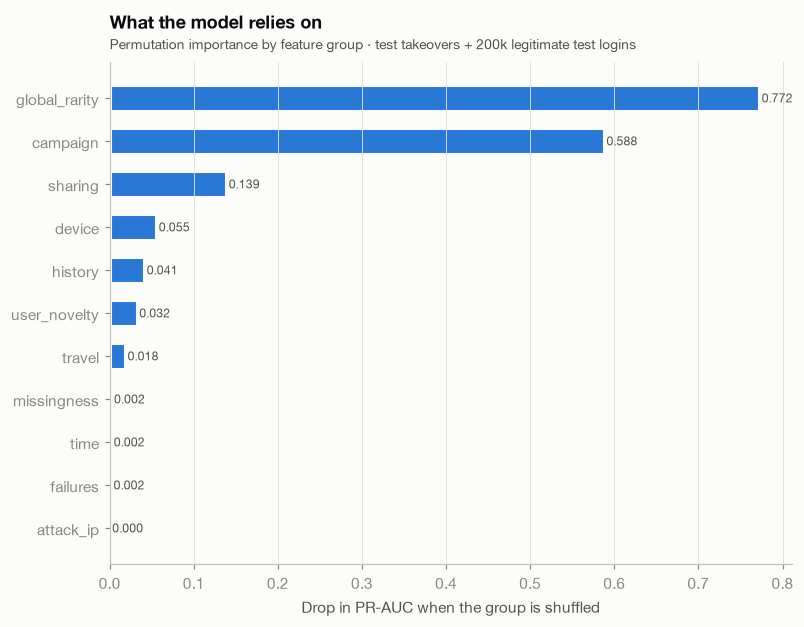

In [11]:
fig, ax = plt.subplots(figsize=(8, 0.42 * importance.height + 1.3))
ordered = importance.sort("PR-AUC drop")
bars = ax.barh(
    ordered["group"],
    ordered["PR-AUC drop"].clip(lower_bound=0),
    color=BLUE,
    height=0.6,
    edgecolor=SURFACE,
    linewidth=2,
)
for bar, value in zip(bars, ordered["PR-AUC drop"], strict=True):
    ax.text(
        max(value, 0) + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=8,
        color=INK_2,
    )
ax.set_xlabel("Drop in PR-AUC when the group is shuffled")
ax.grid(axis="x")
ax.set_title("What the model relies on", pad=22)
subtitle(
    ax, "Permutation importance by feature group · test takeovers + 200k legitimate test logins"
)
save(fig, "permutation_importance")
plt.show()

**SHAP values** explain *individual* scores: how much each input pushed one login's score up or down. They
are computed on every test takeover and 300 random legitimate test logins (exact tree SHAP).

In [12]:
preprocess, model = pipeline.named_steps["preprocess"], pipeline.named_steps["model"]
names = [n.split("__", 1)[-1] for n in preprocess.get_feature_names_out()]
explain_rows = np.sort(
    np.concatenate([np.flatnonzero(yt), rng.choice(np.flatnonzero(~yt), size=300, replace=False)])
)
x_explain = preprocess.transform(to_model_frame(test[explain_rows], columns))
start = time.perf_counter()
values = shap.TreeExplainer(model).shap_values(x_explain)
values = values[..., 1] if values.ndim == 3 else values  # noqa: PLR2004 — (rows, inputs, classes)
print(f"SHAP for {len(explain_rows)} logins in {time.perf_counter() - start:.0f} s")
mean_abs = pl.DataFrame({"input": names, "mean |SHAP|": np.abs(values).mean(axis=0)}).sort(
    "mean |SHAP|", descending=True
)
mean_abs.head(15).with_columns(pl.col("mean |SHAP|").round(4))

SHAP for 328 logins in 4 s


input,mean |SHAP|
str,f64
"""global_share_asn""",0.0564
"""global_share_country""",0.0446
"""asn_prior_users""",0.044
"""global_share_browser""",0.0438
"""asn_attempts_prev24h""",0.0426
"""asn_fails_prev24h""",0.0343
"""user_agent_prior_users""",0.0245
"""asn_prior_attack_share""",0.0231
"""global_share_device_type""",0.023


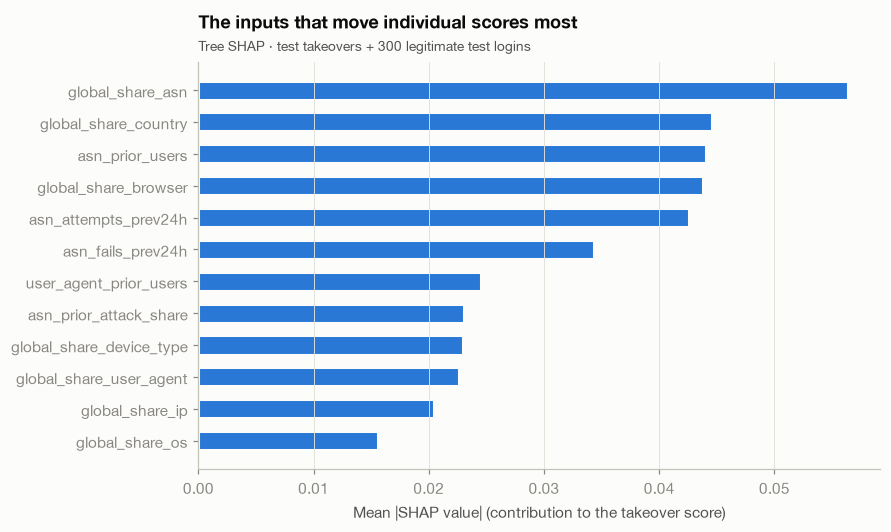

In [13]:
top = mean_abs.head(12).sort("mean |SHAP|")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top["input"], top["mean |SHAP|"], color=BLUE, height=0.6, edgecolor=SURFACE, linewidth=2)
ax.set_xlabel("Mean |SHAP value| (contribution to the takeover score)")
ax.grid(axis="x")
ax.set_title("The inputs that move individual scores most", pad=22)
subtitle(ax, "Tree SHAP · test takeovers + 300 legitimate test logins")
save(fig, "shap_importance")
plt.show()

**Reading (importance).** Both methods agree. **Global rarity dominates**: shuffling it drops PR-AUC from 0.80 to almost nothing; the
model leans first on how rare the network (ASN), country, browser and IP are across all users. The **campaign**
group is second (−0.59): attempts and failures from the network in the last 24 hours, the share of its earlier
attempts from attack IPs, accounts that already used the exact user agent; **sharing** (accounts already seen on
the network or IP) is third (−0.14). Device type, history (dormancy), novelty for the user and impossible travel
add a little (−0.06 to −0.02); time, failures on the account and the attack-IP flag of the login itself add nothing
on top — the network's attack history already carries that information. A caveat: correlated groups hide each
other in permutation importance, so a small value (e.g. *novelty*) does not mean the signal is useless — a
globally rare value is almost always new for the user as well.

## 🧯 5 · Error analysis

What do the flagged legitimate logins look like at the **step-up** threshold (top 1% on development scores), and
which takeovers fall below the stricter **review / block** threshold (top 0.1%)?

In [14]:
flag = score >= thresholds["step-up"]
outcome = (
    pl.when(pl.col("label_ato") & pl.Series(flag))
    .then(pl.lit("takeover · caught"))
    .when(pl.col("label_ato"))
    .then(pl.lit("takeover · missed"))
    .when(pl.Series(flag))
    .then(pl.lit("legitimate · flagged"))
    .otherwise(pl.lit("legitimate · allowed"))
)
KEY = [
    "first_success",
    "new_country",
    "new_asn",
    "attack_ip",
    "country_change_1h",
    "asn_prior_attack_share",
]
errors = test.with_columns(outcome.alias("outcome"), pl.Series("score", score))
(
    errors.group_by("outcome")
    .agg(
        pl.len().alias("logins"),
        *(pl.col(c).cast(pl.Float64).mean().round(3).alias(c) for c in KEY),
        pl.col("global_share_country").median().round(4).alias("median global share of country"),
        pl.col("hours_since_prev_success").median().round(0).alias("median hours since last login"),
        (pl.col("country") == "RO").mean().round(3).alias("share from RO"),
    )
    .sort("outcome")
)

outcome,logins,first_success,new_country,new_asn,attack_ip,country_change_1h,asn_prior_attack_share,median global share of country,median hours since last login,share from RO
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""legitimate · allowed""",1953260,0.28,0.006,0.105,0.059,0.001,0.06,0.6522,98.0,0.001
"""legitimate · flagged""",18692,0.399,0.205,0.363,0.127,0.024,0.138,0.0113,98.0,0.021
"""takeover · caught""",28,0.464,0.867,0.933,0.607,0.2,0.634,0.0014,963.0,0.571


In [15]:
block = score >= thresholds["review / block"]
missed = errors.filter(pl.col("label_ato") & ~pl.Series(block))  # below the review / block tier
print(f"{missed.height} of {int(yt.sum())} takeovers fall below the review / block threshold")
missed.select(
    "event_id",
    "country",
    "score",
    "first_success",
    "new_country",
    "new_asn",
    "attack_ip",
    "global_share_country",
    "hours_since_prev_success",
    "prior_successes",
).sort("score", descending=True)

4 of 28 takeovers fall below the review / block threshold


event_id,country,score,first_success,new_country,new_asn,attack_ip,global_share_country,hours_since_prev_success,prior_successes
u32,cat,f64,bool,bool,bool,bool,f64,f64,u32
9412283,"""RO""",0.02999,false,false,false,true,0.001383,0.178611,1
82947,"""IT""",0.013333,true,null,null,false,0.0018,null,0
273968,"""NO""",0.009998,true,null,null,false,0.642357,null,0
21266387,"""BR""",0.006666,true,null,null,false,0.029118,null,0


In [16]:
flagged = errors.filter(pl.col("outcome") == "legitimate · flagged")
per_user = flagged.group_by("user_id").len().sort("len", descending=True)
print(
    f"{flagged.height:,} legitimate logins flagged, from {per_user.height:,} users; the 10 most-flagged users "
    f"account for {per_user['len'].head(10).sum() / flagged.height:.0%} of them"
)
per_user.head(10)

18,692 legitimate logins flagged, from 13,367 users; the 10 most-flagged users account for 3% of them


user_id,len
i64,u32
-4746260914446075915,96
6792503953987602475,85
9148430508031180780,82
-7740961544132573866,79
-4573890005630504862,65
-7654599524478640403,49
-3515349109848835805,46
8712601662576334582,44
-5933905104709323583,38


**Reading (errors).** **False alarms** (step-up tier): flagged legitimate logins are first logins of an account more often (40% vs
28%), come from a country new for the user (21% vs 0.6%), from a new network (36% vs 11%) or from an attack-IP
address (13% vs 6%), and from globally rare countries (median share 1.1% vs 65%): travellers, new users abroad and
users of unusual networks — legitimate behaviour that looks like an attacker's. They are spread over 13,367 users
(the 10 most-flagged account for 3%), so no single noisy account drives them. Some may be undetected takeovers:
labels are incomplete, so measured precision is a lower bound.

**Missed takeovers** (below the review / block tier, 4 of 28; all four are still caught at step-up):

* **1 Romania takeover came 11 minutes after a previous successful login from Romania** on the same account — most
  likely the attacker's own earlier login, which made the country already "known". It scores just below the
  threshold (0.030 vs 0.033). Attacker activity contaminating the user's history is a blind spot of any
  history-based detector.
* **3 are the first successful login of the account** — no history, so novelty and dormancy say nothing; the cold
  start already seen in the EDA (39% of takeovers). One of them comes from **Norway**, the country of 65% of all
  logins, and not from an attack IP: nothing distinguishes it from a new legitimate user.

Error causes: **class imbalance** (any threshold catching most takeovers flags hundreds of legitimate logins per
takeover), **cold start**, **incomplete labels**, and the **synthesis** (values are frequency-preserving but
artificial, so real-world context such as network type cannot help). No encoding problem or outlier artefact was
found: the synthesis artefacts were tested in issue #6 and add nothing.

## 📈 6 · Learning curve and scalability on the test side

The selected configuration is retrained on a growing random share of the **development users** and measured on
the test side. This is analysis, not selection: nothing is changed based on it.

In [17]:
dev = load_side(config, data_dir, "dev").collect()
draw = (
    dev.select("user_id")
    .unique()
    .sort("user_id")
    .with_columns(pl.Series("u", rng.random(dev["user_id"].n_unique())))
)
u = dev.select("user_id").join(draw, on="user_id", how="left")["u"].to_numpy()
curve = []
for share in (0.25, 0.5, 0.75, 1.0):
    part = dev.filter(pl.Series(u < share))
    start = time.perf_counter()
    sample_share = training_sample(part, negative_share=meta["negative_share"])
    weights = (
        {"model__sample_weight": campaign_weights(sample_share)}
        if meta["campaign_balanced"]
        else {}
    )
    model_share = clone(pipeline).fit(
        to_model_frame(sample_share, columns), sample_share["label_ato"].to_numpy(), **weights
    )
    fit_seconds = time.perf_counter() - start
    s = model_share.predict_proba(to_model_frame(test, columns))[:, 1]
    lo_s, hi_s = bootstrap_pr_auc(yt, s, n_boot=500)
    curve.append({"share of development users": share, "training takeovers": int(part["label_ato"].sum()),
                  "training logins": part.height, "fit seconds": round(fit_seconds, 1),
                  "test PR-AUC": evaluate(yt, s)["pr_auc"], "low": lo_s, "high": hi_s})  # fmt: skip
curve = pl.DataFrame(curve).with_columns(pl.col("test PR-AUC", "low", "high").round(3))
curve

share of development users,training takeovers,training logins,fit seconds,test PR-AUC,low,high
f64,i64,i64,f64,f64,f64,f64
0.25,33,1965777,3.2,0.465,0.301,0.621
0.5,61,3936736,7.9,0.573,0.401,0.723
0.75,83,5908172,14.2,0.579,0.41,0.726
1.0,112,7868084,20.3,0.623,0.448,0.769


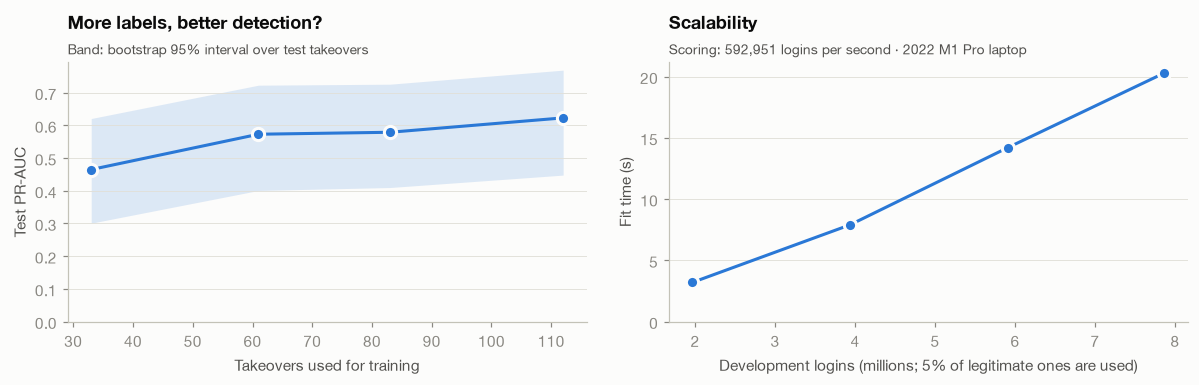

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.fill_between(
    curve["training takeovers"], curve["low"], curve["high"], color=BLUE, alpha=0.15, linewidth=0
)
ax1.plot(
    curve["training takeovers"],
    curve["test PR-AUC"],
    "o-",
    color=BLUE,
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
ax1.set_ylim(0, None)
ax1.set_xlabel("Takeovers used for training")
ax1.set_ylabel("Test PR-AUC")
ax1.grid(axis="y")
ax1.set_title("More labels, better detection?", pad=22)
subtitle(ax1, "Band: bootstrap 95% interval over test takeovers")
ax2.plot(
    curve["training logins"] / 1e6,
    curve["fit seconds"],
    "o-",
    color=BLUE,
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
ax2.set_ylim(0, None)
ax2.set_xlabel("Development logins (millions; 5% of legitimate ones are used)")
ax2.set_ylabel("Fit time (s)")
ax2.grid(axis="y")
ax2.set_title("Scalability", pad=22)
subtitle(
    ax2, f"Scoring: {test.height / scoring_seconds:,.0f} logins per second · 2022 M1 Pro laptop"
)
plt.tight_layout()
save(fig, "learning_curve_scalability")
plt.show()

**Reading (learning curve).** Test PR-AUC rises from **0.47 with 33 training takeovers to 0.57 with 61** and **0.62 with all 112**: more labels
keep helping, though each step after ~60 lies inside the bootstrap interval of the previous one — consistent with
the development learning curve (issue #6). Training time grows linearly (3 → 20 s for 2 → 7.9 M development
logins, of which 5% of legitimate ones are used), and scoring runs at ~600,000 logins per second on a 2022 laptop —
far above the service's real load (~1 login per second on average).

## ✅ Conclusions

* **Final result** (test side): PR-AUC **0.62** [0.45–0.78], **86%** of takeovers in the top 0.1% of logins and
  **100%** in the top 1%, against a chance level of 1.4 × 10⁻⁵ — consistent with the development estimate (0.45)
  within the uncertainty of 28 test takeovers.
* **Thresholds set on development data hold on new users**: the two tiers flag 0.09% and 0.95% of test logins. The
  cost is low precision — 76 false alarms per takeover at review/block, 668 at step-up — which suits a step-up
  (second-factor) response, not blocking.
* **What the model relies on**: global rarity of the login's values first, then attacker-infrastructure signals
  (recent activity and attack-IP history of the network, a user agent shared across accounts, accounts already seen
  on the network), then dormancy, novelty for the user and impossible travel.
* **Where it fails**: first logins (no history), takeovers from the service's home country, and attacker logins that
  follow an earlier attacker login on the same account. False alarms are travellers and users of rare networks.
* **More labels** keep helping (test PR-AUC 0.47 → 0.62 from 33 to 112 training takeovers).
* Limits: 28 test takeovers make every test number uncertain (hence the intervals); the data are synthetic; labels are
  incomplete, so precision is a lower bound.

These results answer **OE4** (Recall, Precision, PR-AUC, thresholds and error analysis). Issue #8 builds the
demonstrable prototype on top of the saved model and thresholds.